<a href="https://colab.research.google.com/github/triprasetyaningsih7700-max/index-html/blob/main/k_means_mesin_pertemuan9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Mmebaca dataset

In [ ]:
df = pd.read_csv("Mall_Customers.csv")
print("Kolom yang tersedia di file:")
print(df.columns)
#202431049_TriPrasetya

Kolom yang tersedia di file:
Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


Fitur yang digunakan untuk clustering

In [ ]:
df = df[['Annual Income (k$)', 'Spending Score (1-100)']]
print(df)

     Annual Income (k$)  Spending Score (1-100)
0                    15                      39
1                    15                      81
2                    16                       6
3                    16                      77
4                    17                      40
..                  ...                     ...
195                 120                      79
196                 126                      28
197                 126                      74
198                 137                      18
199                 137                      83

[200 rows x 2 columns]


<function matplotlib.pyplot.show(close=None, block=None)>

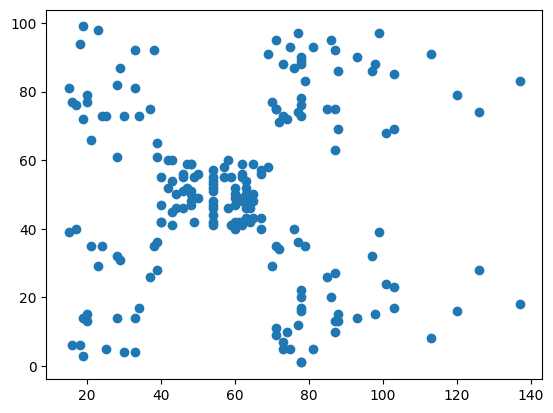

In [ ]:
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'])
plt.show

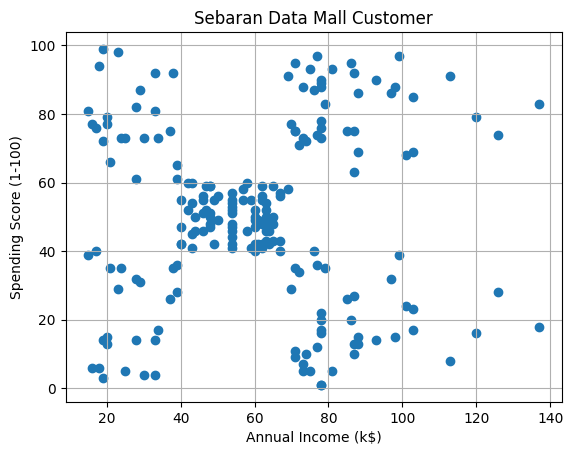

In [ ]:
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Sebaran Data Mall Customer')
plt.grid(True)
plt.show()

In [ ]:
x_array = np.array(df)

standardisasi fitur

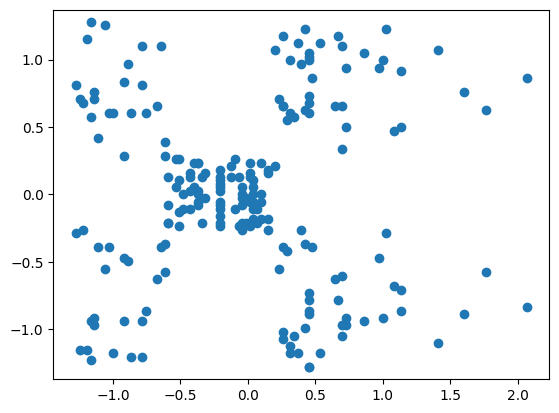

In [ ]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
x_scaled = scaler.fit_transform(x_array)

plt.scatter(x_scaled[:, 0], x_scaled[:, 1])
plt.axis('equal')
plt.show()

menentukan jumlah kluster

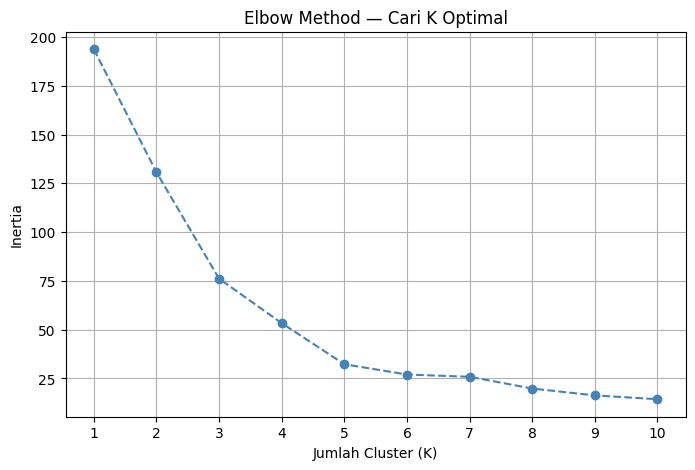

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=0)
    kmeans_temp.fit(x_scaled)
    inertia.append(kmeans_temp.inertia_)


plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='steelblue')
plt.title('Elbow Method — Cari K Optimal')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(k_range)
plt.grid(True)
plt.show()
#elbow metode siku

pelatihan k-means

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters = 5, random_state=0)
kmeans.fit(x_scaled)

KMeans(n_clusters=5, random_state=0)

In [ ]:
kmeans.cluster_centers_

array([[-0.16996449, -0.01258775],
       [ 0.68598525,  0.83995308],
       [-0.98007472,  0.76767677],
       [ 0.73150685, -0.85975724],
       [-0.96426444, -0.76044331]])

<function matplotlib.pyplot.show(close=None, block=None)>

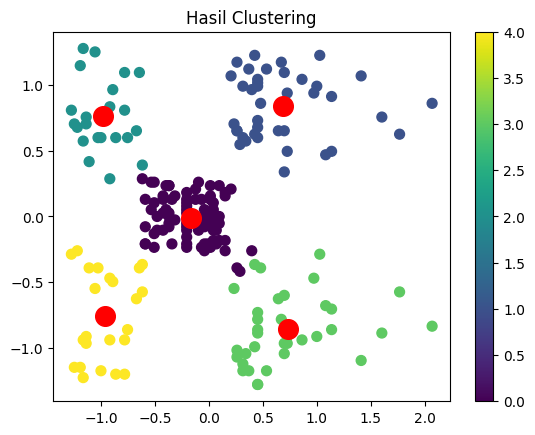

In [ ]:
output = plt.scatter(x_scaled[:,0],
                     x_scaled[:,1],
                     s= 50,
                     c = kmeans.labels_)
centers = kmeans.cluster_centers_

plt.scatter(centers[:,0], centers[:,1], c = 'red', s=200)
plt.title("Hasil Clustering")
plt.colorbar(output)
plt.show

In [ ]:
from sklearn.metrics import davies_bouldin_score
labels = kmeans.labels_
davies_bouldin_score(x_scaled, labels)

np.float64(0.5733769537534885)